In [1]:
from pathlib import Path
import sys

ML_DIR = Path(r"D:\FloodVision-AI\ml")

SRC_DIR = ML_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

PRODUCTION_DIR = ML_DIR / "artifacts" / "production"

print("ML directory:", ML_DIR)
print("Production directory:", PRODUCTION_DIR)
print("Python:", sys.version)

ML directory: D:\FloodVision-AI\ml
Production directory: D:\FloodVision-AI\ml\artifacts\production
Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [2]:
import importlib
import importlib.metadata

packages = {
    "numpy": "numpy",
    "rasterio": "rasterio",
    "pyproj": "pyproj",
    "shapely": "shapely",
    "geopandas": "geopandas",
    "affine": "affine"
}

missing_packages = []

for module, package in packages.items():

    try:

        importlib.import_module(module)

        version = importlib.metadata.version(package)

        print(f"[PASS] {package}: {version}")

    except ImportError:

        missing_packages.append(package)

        print(f"[MISSING] {package}")

print("\nMissing packages:", missing_packages)

[PASS] numpy: 2.5.4
[PASS] rasterio: 1.5.2
[PASS] pyproj: 3.8.0
[PASS] shapely: 2.2.0
[PASS] geopandas: 1.2.0
[PASS] affine: 3.0.1

Missing packages: []


In [3]:
%pip install pyproj shapely geopandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import rasterio
import yaml
import json

from floodvision.inference.model_loader import ModelLoader

from floodvision.inference.tiled_predictor import (
    TiledInferenceEngine
)

from floodvision.inference.geospatial import (
    GeospatialAnalyzer
)

loader = ModelLoader(PRODUCTION_DIR)

engine = TiledInferenceEngine(
    loader=loader,
    device="auto",
    require_crs=True,
    allow_unverified_band_order=False
)

print("Production engine ready!")
print("Device:", loader.device)

Production engine ready!
Device: cpu


In [5]:
with open(
    ML_DIR / "configs" / "dataset.yaml",
    "r"
) as file:

    dataset_config = yaml.safe_load(file)["dataset"]

val_samples = pd.read_csv(
    ML_DIR / "data/splits/geographical/val.csv"
)

sample_id = val_samples.iloc[0]["sample_id"]

sample_path = (
    ML_DIR
    / dataset_config["root_dir"]
    / dataset_config["image_dir"]
    / f"{sample_id}_S1Hand.tif"
)

metadata = engine.reader.get_metadata(
    sample_path
)

print("Sample:", sample_id)
print("CRS:", metadata.crs)
print("Width:", metadata.width)
print("Height:", metadata.height)

print("\nAffine coefficients:")

for name in ["a", "b", "c", "d", "e", "f"]:

    print(
        name,
        "=",
        getattr(metadata.transform, name)
    )

Sample: Mekong_1111068
CRS: EPSG:4326
Width: 512
Height: 512

Affine coefficients:
a = 8.983152841195215e-05
b = 0.0
c = 105.83160160046177
d = 0.0
e = -8.983152841195215e-05
f = 12.05036054729291


In [6]:
analyzer = GeospatialAnalyzer(metadata)

geo_info = analyzer.analyze()

print("=" * 55)
print("GEOSPATIAL METADATA")
print("=" * 55)

print(
    json.dumps(
        geo_info.to_dict(),
        indent=4,
        allow_nan=False
    )
)

GEOSPATIAL METADATA
{
    "width": 512,
    "height": 512,
    "crs": "EPSG:4326",
    "crs_type": "geographic",
    "coordinate_unit": "degree",
    "bounds": {
        "left": 105.83160160046177,
        "bottom": 12.00436680474599,
        "right": 105.8775953430087,
        "top": 12.05036054729291
    },
    "resolution": {
        "x": 8.983152841195215e-05,
        "y": 8.983152841195215e-05,
        "unit": "degree"
    },
    "center": {
        "x": 105.85459847173523,
        "y": 12.02736367601945,
        "longitude": 105.85459847173523,
        "latitude": 12.02736367601945
    },
    "affine_transform": [
        8.983152841195215e-05,
        0.0,
        105.83160160046177,
        0.0,
        -8.983152841195215e-05,
        12.05036054729291
    ]
}


In [7]:
test_pixels = [
    (0, 0),
    (0, 511),
    (256, 256),
    (511, 0),
    (511, 511)
]

with rasterio.open(sample_path) as src:

    for row, col in test_pixels:

        x, y = analyzer.pixel_to_coordinates(
            row,
            col
        )

        expected_x, expected_y = src.xy(
            row,
            col
        )

        assert np.allclose(
            [x, y],
            [expected_x, expected_y],
            rtol=0,
            atol=1e-10
        )

        lon, lat = analyzer.pixel_to_lonlat(
            row,
            col
        )

        print(
            f"Pixel ({row}, {col}) | "
            f"Longitude: {lon:.8f} | "
            f"Latitude: {lat:.8f}"
        )

print("\nPixel coordinate transformation PASSED!")

Pixel (0, 0) | Longitude: 105.83164652 | Latitude: 12.05031563
Pixel (0, 511) | Longitude: 105.87755043 | Latitude: 12.05031563
Pixel (256, 256) | Longitude: 105.85464339 | Latitude: 12.02731876
Pixel (511, 0) | Longitude: 105.83164652 | Latitude: 12.00441172
Pixel (511, 511) | Longitude: 105.87755043 | Latitude: 12.00441172

Pixel coordinate transformation PASSED!


In [8]:
with rasterio.open(sample_path) as src:

    expected_bounds = tuple(src.bounds)

    expected_resolution = src.res

assert np.allclose(
    geo_info.bounds,
    expected_bounds,
    rtol=0,
    atol=1e-10
)

assert np.allclose(
    [
        geo_info.resolution_x,
        geo_info.resolution_y
    ],
    expected_resolution,
    rtol=0,
    atol=1e-10
)

print("Calculated bounds:", geo_info.bounds)
print("Rasterio bounds:", expected_bounds)

print("\nCalculated resolution:")

print("X:", geo_info.resolution_x)
print("Y:", geo_info.resolution_y)
print("Unit:", geo_info.coordinate_unit)

print("\n[PASS] Raster bounds")
print("[PASS] Spatial resolution")

print("\nGeospatial metadata validation PASSED!")

Calculated bounds: (105.83160160046177, 12.00436680474599, 105.8775953430087, 12.05036054729291)
Rasterio bounds: (105.83160160046177, 12.00436680474599, 105.8775953430087, 12.05036054729291)

Calculated resolution:
X: 8.983152841195215e-05
Y: 8.983152841195215e-05
Unit: degree

[PASS] Raster bounds
[PASS] Spatial resolution

Geospatial metadata validation PASSED!


In [9]:
import pyproj
import shapely
import geopandas

from floodvision.inference.raster_exporter import (
    RasterExporter
)

print("PyProj:", pyproj.__version__)
print("Shapely:", shapely.__version__)
print("GeoPandas:", geopandas.__version__)

exporter = RasterExporter(
    block_size=256
)

EXPORT_DIR = (
    ML_DIR
    / "artifacts"
    / "geospatial_validation"
)

EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("\nRaster exporter initialized!")
print("Block size:", exporter.block_size)
print("Output directory:", EXPORT_DIR)

PyProj: 3.8.0
Shapely: 2.2.0
GeoPandas: 1.2.0

Raster exporter initialized!
Block size: 256
Output directory: D:\FloodVision-AI\ml\artifacts\geospatial_validation


In [10]:
mask_path = (
    EXPORT_DIR
    / f"{sample_id}_water_mask.tif"
)

probability_path = (
    EXPORT_DIR
    / f"{sample_id}_water_probability.tif"
)

with engine.predict(
    sample_path,
    storage="memory"
) as result:

    exporter.export_mask(
        mask=result.mask,
        metadata=result.metadata,
        output_path=mask_path,
        model_version=result.model_version,
        threshold=result.threshold,
        overwrite=True
    )

    exporter.export_probabilities(
        probabilities=result.probabilities,
        metadata=result.metadata,
        output_path=probability_path,
        model_version=result.model_version,
        threshold=result.threshold,
        overwrite=True
    )

    reference_mask = result.mask.copy()

    reference_probabilities = (
        result.probabilities.copy()
    )

    prediction_summary = result.to_summary()

print("=" * 55)
print("GEOTIFF EXPORT RESULTS")
print("=" * 55)

for path in [mask_path, probability_path]:

    print("\nFile:", path.name)

    print(
        "Size:",
        round(path.stat().st_size / 1024, 2),
        "KiB"
    )

print(
    "\nWater coverage:",
    prediction_summary["statistics"]["water_coverage"]
)

print("\nGeoTIFF export PASSED!")

GEOTIFF EXPORT RESULTS

File: Mekong_1111068_water_mask.tif
Size: 10.89 KiB

File: Mekong_1111068_water_probability.tif
Size: 933.86 KiB

Water coverage: 25.217437744140625

GeoTIFF export PASSED!


In [11]:
with rasterio.open(mask_path) as src:

    exported_mask = src.read(1)

    print("Driver:", src.driver)
    print("Dimensions:", src.shape)
    print("Bands:", src.count)
    print("Dtype:", src.dtypes)
    print("CRS:", src.crs)
    print("NoData:", src.nodata)
    print("Compression:", src.compression)
    print("Block shapes:", src.block_shapes)
    print("Labels:", np.unique(exported_mask))
    print("Tags:", src.tags())

    assert src.driver == "GTiff"

    assert src.count == 1

    assert src.dtypes[0] == "int8"

    assert src.nodata == -1

    assert src.crs == metadata.crs

    assert src.transform == metadata.transform

    assert src.shape == (
        metadata.height,
        metadata.width
    )

    assert np.array_equal(
        exported_mask,
        reference_mask
    )

    assert np.array_equal(
        src.read_masks(1) > 0,
        reference_mask != -1
    )

print("\n[PASS] CRS preservation")
print("[PASS] Affine preservation")
print("[PASS] Mask pixel equivalence")
print("[PASS] NoData validity")

print("\nSegmentation GeoTIFF PASSED!")

Driver: GTiff
Dimensions: (512, 512)
Bands: 1
Dtype: ('int8',)
CRS: EPSG:4326
NoData: -1.0
Compression: Compression.deflate
Block shapes: [(256, 256)]
Labels: [0 1]
Tags: {'LABEL_INVALID': '-1', 'LABEL_NON_WATER': '0', 'LABEL_WATER': '1', 'MODEL_VERSION': '1.0.0', 'OUTPUT_TYPE': 'mask', 'PROJECT': 'FloodVision AI', 'SOURCE_FILE': 'Mekong_1111068_S1Hand.tif', 'TASK': 'binary_water_segmentation', 'THRESHOLD': '0.5', 'AREA_OR_POINT': 'Area'}

[PASS] CRS preservation
[PASS] Affine preservation
[PASS] Mask pixel equivalence
[PASS] NoData validity

Segmentation GeoTIFF PASSED!


In [12]:
with rasterio.open(probability_path) as src:

    exported_probabilities = src.read(1)

    print("Driver:", src.driver)
    print("Dimensions:", src.shape)
    print("Dtype:", src.dtypes)
    print("CRS:", src.crs)
    print("NoData:", src.nodata)

    assert src.count == 1

    assert src.dtypes[0] == "float32"

    assert np.isnan(src.nodata)

    assert src.crs == metadata.crs

    assert src.transform == metadata.transform

    assert np.array_equal(
        exported_probabilities,
        reference_probabilities,
        equal_nan=True
    )

    assert np.array_equal(
        src.read_masks(1) > 0,
        np.isfinite(reference_probabilities)
    )

    valid = np.isfinite(
        exported_probabilities
    )

    print(
        "Minimum probability:",
        exported_probabilities[valid].min()
    )

    print(
        "Maximum probability:",
        exported_probabilities[valid].max()
    )

print("\n[PASS] CRS preservation")
print("[PASS] Affine preservation")
print("[PASS] Exact probability equivalence")
print("[PASS] NoData validity")

print("\nProbability GeoTIFF PASSED!")

Driver: GTiff
Dimensions: (512, 512)
Dtype: ('float32',)
CRS: EPSG:4326
NoData: nan
Minimum probability: 0.00023584398
Maximum probability: 0.9827195

[PASS] CRS preservation
[PASS] Affine preservation
[PASS] Exact probability equivalence
[PASS] NoData validity

Probability GeoTIFF PASSED!


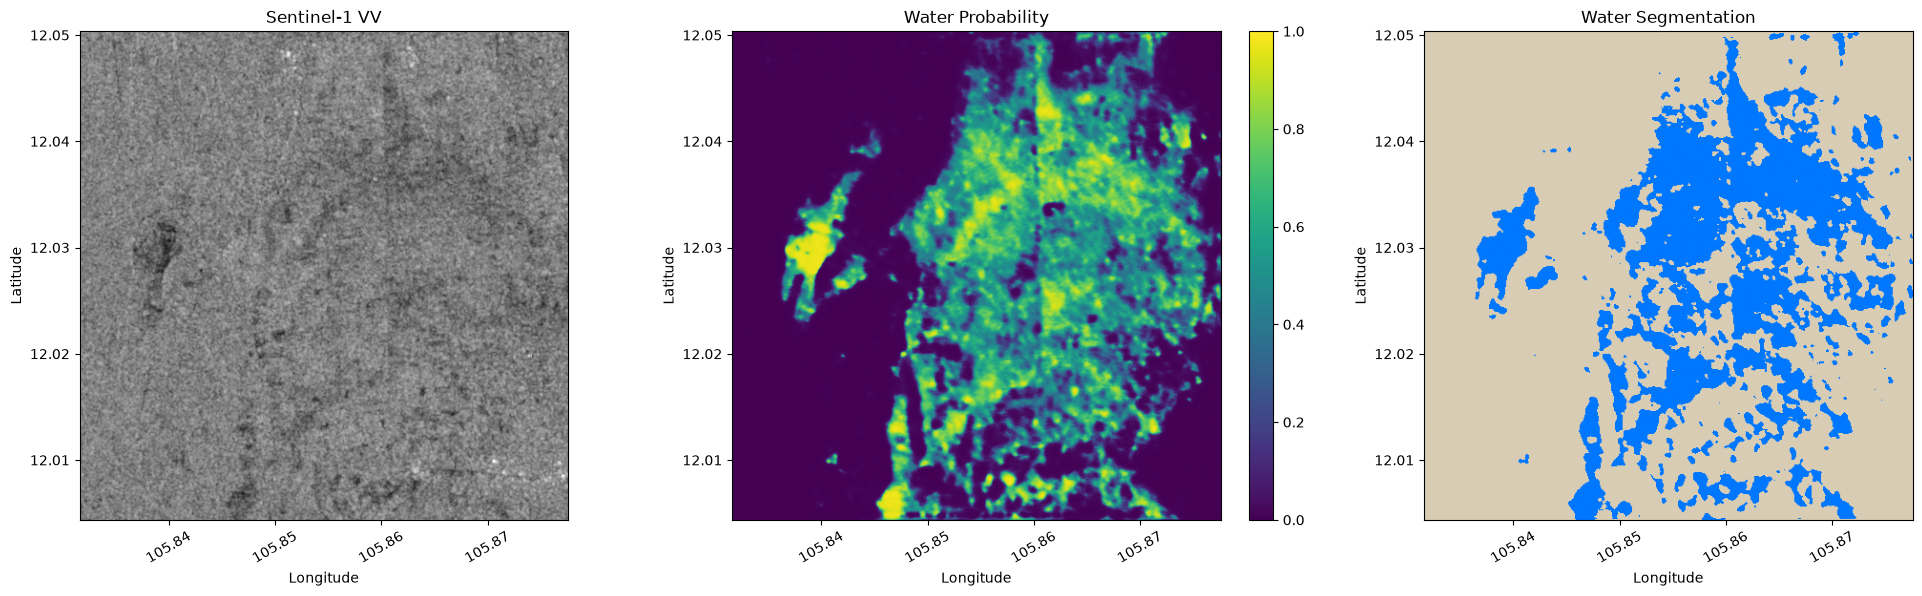

In [13]:
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap
from rasterio.plot import plotting_extent

with rasterio.open(sample_path) as src:

    vv = src.read(1)

    extent = plotting_extent(src)

mask_cmap = ListedColormap([
    "#808080",
    "#d8cdb4",
    "#0077ff"
])

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6)
)

axes[0].imshow(
    vv,
    cmap="gray",
    extent=extent
)

axes[0].set_title("Sentinel-1 VV")

probability_plot = axes[1].imshow(
    exported_probabilities,
    cmap="viridis",
    vmin=0,
    vmax=1,
    extent=extent
)

axes[1].set_title("Water Probability")

fig.colorbar(
    probability_plot,
    ax=axes[1],
    fraction=0.046
)

axes[2].imshow(
    exported_mask,
    cmap=mask_cmap,
    vmin=-1,
    vmax=1,
    extent=extent
)

axes[2].set_title("Water Segmentation")

for ax in axes:

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.ticklabel_format(
        style="plain",
        useOffset=False
    )

    ax.tick_params(
        axis="x",
        labelrotation=30
    )

plt.tight_layout()
plt.show()

In [14]:
invalid_test_path = (
    EXPORT_DIR / "synthetic_invalid_sar.tif"
)

with rasterio.open(sample_path) as src:

    synthetic_image = src.read().astype(
        np.float32
    )

    synthetic_profile = src.profile.copy()

synthetic_image[:, :128, :128] = np.nan

synthetic_profile.update(
    dtype="float32",
    nodata=np.nan
)

with rasterio.open(
    invalid_test_path,
    "w",
    **synthetic_profile
) as dst:

    dst.write(synthetic_image)

    dst.set_band_description(1, "VV")
    dst.set_band_description(2, "VH")


disk_mask_path = (
    EXPORT_DIR / "disk_validation_mask.tif"
)

disk_probability_path = (
    EXPORT_DIR / "disk_validation_probability.tif"
)

with engine.predict(
    invalid_test_path,
    storage="disk",
    work_dir=EXPORT_DIR
) as result:

    assert isinstance(
        result.mask,
        np.memmap
    )

    exporter.export_mask(
        mask=result.mask,
        metadata=result.metadata,
        output_path=disk_mask_path,
        model_version=result.model_version,
        threshold=result.threshold,
        overwrite=True
    )

    exporter.export_probabilities(
        probabilities=result.probabilities,
        metadata=result.metadata,
        output_path=disk_probability_path,
        model_version=result.model_version,
        threshold=result.threshold,
        overwrite=True
    )

    expected_invalid = (
        result.statistics["invalid_pixels"]
    )

# Accumulator is now closed.
# Exported GeoTIFF files remain available.

with rasterio.open(disk_mask_path) as src:

    disk_mask = src.read(1)

    assert np.all(
        disk_mask[:128, :128] == -1
    )

    assert int(
        (disk_mask == -1).sum()
    ) == expected_invalid

with rasterio.open(disk_probability_path) as src:

    disk_probs = src.read(1)

    assert np.isnan(
        disk_probs[:128, :128]
    ).all()

    assert np.array_equal(
        np.isnan(disk_probs),
        disk_mask == -1
    )

assert not list(
    EXPORT_DIR.glob(
        "floodvision_accumulator_*"
    )
)

print("Invalid pixels:", expected_invalid)

print("[PASS] Disk-backed export")
print("[PASS] Invalid mask labels")
print("[PASS] Invalid probabilities")
print("[PASS] Persistent GeoTIFF files")
print("[PASS] Temporary resource cleanup")

print("\nDisk-backed GeoTIFF export PASSED!")

Invalid pixels: 16384
[PASS] Disk-backed export
[PASS] Invalid mask labels
[PASS] Invalid probabilities
[PASS] Persistent GeoTIFF files
[PASS] Temporary resource cleanup

Disk-backed GeoTIFF export PASSED!


In [15]:
from floodvision.inference.exceptions import (
    GeospatialError
)

def expect_rejection(name, function):

    try:

        function()

    except GeospatialError as exc:

        print(f"[PASS] {name}")
        print(f"Reason: {exc}\n")

    else:

        raise AssertionError(
            f"Expected rejection: {name}"
        )


expect_rejection(
    "Incorrect mask dimensions",
    lambda: exporter.export_mask(
        np.zeros((256, 256), dtype=np.int8),
        metadata,
        EXPORT_DIR / "invalid_shape.tif"
    )
)

expect_rejection(
    "Incorrect mask dtype",
    lambda: exporter.export_mask(
        reference_mask.astype(np.float32),
        metadata,
        EXPORT_DIR / "invalid_dtype.tif"
    )
)

expect_rejection(
    "Invalid segmentation labels",
    lambda: exporter.export_mask(
        np.full(
            reference_mask.shape,
            5,
            dtype=np.int8
        ),
        metadata,
        EXPORT_DIR / "invalid_labels.tif"
    )
)

expect_rejection(
    "Invalid probability range",
    lambda: exporter.export_probabilities(
        np.full(
            reference_mask.shape,
            1.5,
            dtype=np.float32
        ),
        metadata,
        EXPORT_DIR / "invalid_probability.tif"
    )
)

expect_rejection(
    "Existing output protection",
    lambda: exporter.export_mask(
        reference_mask,
        metadata,
        mask_path
    )
)

expect_rejection(
    "Source raster protection",
    lambda: exporter.export_mask(
        reference_mask,
        metadata,
        sample_path,
        overwrite=True
    )
)

assert not list(
    EXPORT_DIR.glob(".*.tmp.tif")
)

print("All raster export rejection tests PASSED!")

[PASS] Incorrect mask dimensions
Reason: Expected shape (512, 512), received (256, 256).

[PASS] Incorrect mask dtype
Reason: Mask must have int8 dtype.

[PASS] Invalid segmentation labels
Reason: Invalid segmentation labels.

[PASS] Invalid probability range
Reason: Probabilities must be between 0 and 1.

[PASS] Existing output protection
Reason: Output already exists: D:\FloodVision-AI\ml\artifacts\geospatial_validation\Mekong_1111068_water_mask.tif

[PASS] Source raster protection
Reason: Cannot overwrite source raster.

All raster export rejection tests PASSED!


In [16]:
from floodvision.inference.area_analyzer import (
    AreaAnalyzer
)

area_analyzer = AreaAnalyzer(metadata)

row_areas = area_analyzer.get_row_areas()

print("=" * 55)
print("GEODESIC PIXEL AREA")
print("=" * 55)

print("Rows:", len(row_areas))
print("Dtype:", row_areas.dtype)

print("First row area:", row_areas[0], "m²")

print(
    "Middle row area:",
    row_areas[len(row_areas) // 2],
    "m²"
)

print("Last row area:", row_areas[-1], "m²")

print("Minimum area:", row_areas.min())
print("Maximum area:", row_areas.max())
print("Mean area:", row_areas.mean())

assert np.isfinite(row_areas).all()
assert (row_areas > 0).all()

print("\nGeodesic pixel area PASSED!")

GEODESIC PIXEL AREA
Rows: 512
Dtype: float64
First row area: 97.19848944433033 m²
Middle row area: 97.2065966501832 m²
Last row area: 97.21465696208179 m²
Minimum area: 97.19848944433033
Maximum area: 97.21465696208179
Mean area: 97.20657827541436

Geodesic pixel area PASSED!


In [17]:
area_stats = area_analyzer.analyze(
    exported_mask
)

print("=" * 55)
print("SATELLITE WATER AREA ANALYTICS")
print("=" * 55)

print(
    json.dumps(
        area_stats.to_dict(),
        indent=4,
        allow_nan=False
    )
)

print(
    "\nPredicted water area:",
    round(area_stats.water_area_km2, 6),
    "km²"
)

print(
    "Predicted water area:",
    round(area_stats.water_area_hectares, 4),
    "hectares"
)

print("\nWater area analytics PASSED!")

SATELLITE WATER AREA ANALYTICS
{
    "method": "wgs84_geodesic_row_weighted",
    "total_area_m2": 25482121.25543022,
    "valid_area_m2": 25482121.25543022,
    "invalid_area_m2": 0.0,
    "water_area_m2": 6425933.139488682,
    "non_water_area_m2": 19056188.11594154,
    "water_area_km2": 6.4259331394886825,
    "water_area_hectares": 642.5933139488682,
    "water_area_percentage": 25.21741842084407
}

Predicted water area: 6.425933 km²
Predicted water area: 642.5933 hectares

Water area analytics PASSED!


In [18]:
expected_total_area = (
    row_areas.sum()
    * metadata.width
)

assert np.isclose(
    area_stats.total_area_m2,
    expected_total_area,
    rtol=1e-10
)

assert np.isclose(
    area_stats.total_area_m2,
    area_stats.valid_area_m2
    + area_stats.invalid_area_m2
)

assert np.isclose(
    area_stats.valid_area_m2,
    area_stats.water_area_m2
    + area_stats.non_water_area_m2
)

assert area_stats.invalid_area_m2 == 0

assert 0 <= area_stats.water_area_percentage <= 100

print("[PASS] Total area conservation")
print("[PASS] Valid area conservation")
print("[PASS] Invalid area consistency")
print("[PASS] Water percentage range")

print("\nArea conservation PASSED!")

[PASS] Total area conservation
[PASS] Valid area conservation
[PASS] Invalid area consistency
[PASS] Water percentage range

Area conservation PASSED!


In [19]:
pixel_coverage = (
    np.count_nonzero(exported_mask == 1)
    / np.count_nonzero(exported_mask != -1)
    * 100
)

geographical_coverage = (
    area_stats.water_area_percentage
)

difference = (
    geographical_coverage
    - pixel_coverage
)

print("Pixel coverage:", pixel_coverage, "%")

print(
    "Geographical area coverage:",
    geographical_coverage,
    "%"
)

print(
    "Difference:",
    difference,
    "percentage points"
)

Pixel coverage: 25.217437744140625 %
Geographical area coverage: 25.21741842084407 %
Difference: -1.9323296555739944e-05 percentage points


In [20]:
test_pixels = [
    (0, 0),
    (0, 511),
    (100, 200),
    (256, 256),
    (511, 0),
    (511, 511)
]

for row, col in test_pixels:

    direct_area = (
        area_analyzer.pixel_area_m2(
            row,
            col
        )
    )

    cached_area = row_areas[row]

    assert np.isclose(
        direct_area,
        cached_area,
        rtol=1e-6,
        atol=1e-4
    )

    print(
        f"[PASS] Pixel ({row}, {col}) | "
        f"Area: {direct_area:.6f} m²"
    )

print("\nRow-based optimization PASSED!")

[PASS] Pixel (0, 0) | Area: 97.198489 m²
[PASS] Pixel (0, 511) | Area: 97.198489 m²
[PASS] Pixel (100, 200) | Area: 97.201658 m²
[PASS] Pixel (256, 256) | Area: 97.206597 m²
[PASS] Pixel (511, 0) | Area: 97.214657 m²
[PASS] Pixel (511, 511) | Area: 97.214657 m²

Row-based optimization PASSED!


In [21]:
shape = (
    metadata.height,
    metadata.width
)

test_cases = [
    ("All water", 1),
    ("All non-water", 0),
    ("All invalid", -1)
]

for name, label in test_cases:

    test_mask = np.full(
        shape,
        label,
        dtype=np.int8
    )

    stats = area_analyzer.analyze(
        test_mask
    )

    if label == 1:

        assert np.isclose(
            stats.water_area_m2,
            stats.total_area_m2
        )

        assert stats.water_area_percentage == 100

    elif label == 0:

        assert stats.water_area_m2 == 0

        assert stats.water_area_percentage == 0

    else:

        assert stats.valid_area_m2 == 0

        assert stats.water_area_percentage is None

        assert np.isclose(
            stats.invalid_area_m2,
            stats.total_area_m2
        )

    print(f"[PASS] {name}")

print("\nExtreme classification tests PASSED!")

[PASS] All water
[PASS] All non-water
[PASS] All invalid

Extreme classification tests PASSED!


In [22]:
with engine.predict(
    invalid_test_path,
    storage="disk",
    work_dir=EXPORT_DIR
) as result:

    assert isinstance(
        result.mask,
        np.memmap
    )

    disk_analyzer = AreaAnalyzer(
        result.metadata
    )

    disk_area_stats = (
        disk_analyzer.analyze(
            result.mask
        )
    )

    assert disk_area_stats.invalid_area_m2 > 0

    assert np.isclose(
        disk_area_stats.total_area_m2,
        area_stats.total_area_m2
    )

    assert np.isclose(
        disk_area_stats.total_area_m2,
        disk_area_stats.valid_area_m2
        + disk_area_stats.invalid_area_m2
    )

print(
    json.dumps(
        disk_area_stats.to_dict(),
        indent=4,
        allow_nan=False
    )
)

print("\nDisk-backed area analytics PASSED!")

{
    "method": "wgs84_geodesic_row_weighted",
    "total_area_m2": 25482121.255430236,
    "valid_area_m2": 23889588.23595573,
    "invalid_area_m2": 1592533.0194745064,
    "water_area_m2": 3202857.6990487706,
    "non_water_area_m2": 20686730.536906958,
    "water_area_km2": 3.2028576990487707,
    "water_area_hectares": 320.28576990487704,
    "water_area_percentage": 13.406918810882706
}

Disk-backed area analytics PASSED!


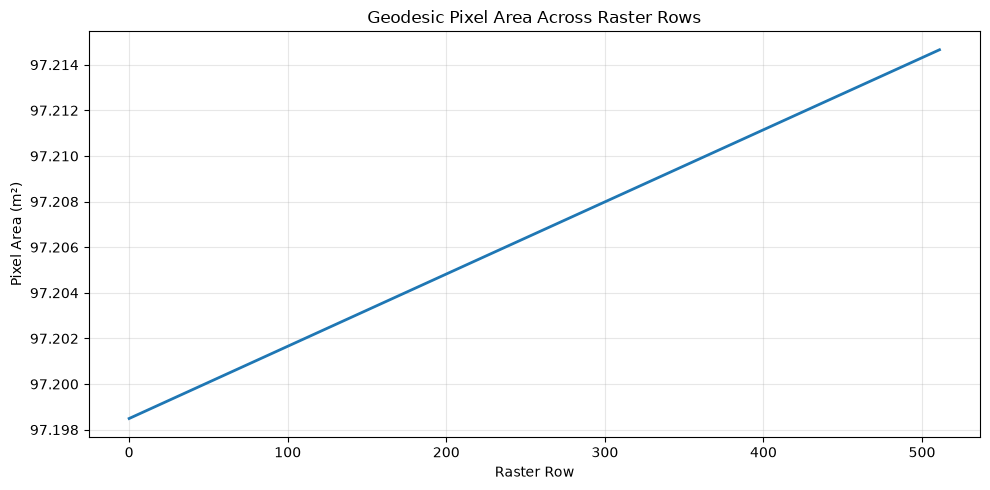

In [23]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    np.arange(metadata.height),
    row_areas,
    linewidth=2
)

ax.set_title(
    "Geodesic Pixel Area Across Raster Rows"
)

ax.set_xlabel("Raster Row")
ax.set_ylabel("Pixel Area (m²)")

ax.ticklabel_format(
    axis="y",
    style="plain",
    useOffset=False
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
area_summary_path = (
    EXPORT_DIR
    / f"{sample_id}_area_statistics.json"
)

area_summary = {
    "sample_id": sample_id,
    "model_version": "1.0.0",
    "task": "binary_water_segmentation",
    "geospatial": geo_info.to_dict(),
    "area_statistics": area_stats.to_dict()
}

with open(
    area_summary_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        area_summary,
        file,
        indent=4,
        allow_nan=False
    )

print("Saved:", area_summary_path.name)

print(
    "\nArea analytics artifact saved!"
)

Saved: Mekong_1111068_area_statistics.json

Area analytics artifact saved!


In [25]:
from floodvision.inference.vectorizer import (
    WaterVectorizer
)

vectorizer = WaterVectorizer(
    connectivity=4,
    max_pixels=4_000_000,
    max_regions=100_000
)

print("Water vectorizer initialized!")

print(
    "Connectivity:",
    vectorizer.connectivity
)

print(
    "Maximum pixels:",
    vectorizer.max_pixels
)

print(
    "Maximum regions:",
    vectorizer.max_regions
)

Water vectorizer initialized!
Connectivity: 4
Maximum pixels: 4000000
Maximum regions: 100000


In [26]:
import time

start = time.perf_counter()

vector_result = vectorizer.vectorize(
    exported_mask,
    metadata
)

vectorization_ms = (
    time.perf_counter() - start
) * 1000

print("=" * 55)
print("WATER REGION EXTRACTION")
print("=" * 55)

print(
    json.dumps(
        vector_result.to_summary(),
        indent=4,
        allow_nan=False
    )
)

print(
    "\nVectorization time:",
    round(vectorization_ms, 4),
    "ms"
)

assert vector_result.region_count > 0

print("\nWater polygon extraction PASSED!")

WATER REGION EXTRACTION
{
    "crs": "EPSG:4326",
    "connectivity": 4,
    "region_count": 182,
    "total_area_m2": 6425933.066247962,
    "total_area_km2": 6.425933066247962,
    "largest_region": {
        "region_id": 103,
        "geometry_type": "Polygon",
        "area_m2": 3526187.5759237446,
        "area_km2": 3.5261875759237444,
        "area_hectares": 352.61875759237444
    }
}

Vectorization time: 151.5896 ms

Water polygon extraction PASSED!


In [27]:
for region in vector_result.regions:

    assert not region.geometry.is_empty

    assert region.geometry.is_valid

    assert region.geometry.geom_type in (
        "Polygon",
        "MultiPolygon"
    )

    assert region.area_m2 > 0

region_ids = [
    region.region_id
    for region in vector_result.regions
]

assert len(region_ids) == len(set(region_ids))

print("Total regions:", len(region_ids))

print("[PASS] Non-empty geometries")
print("[PASS] Geometry validity")
print("[PASS] Polygon geometry types")
print("[PASS] Positive geographical areas")
print("[PASS] Unique region identifiers")

print("\nGeometry integrity PASSED!")

Total regions: 182
[PASS] Non-empty geometries
[PASS] Geometry validity
[PASS] Polygon geometry types
[PASS] Positive geographical areas
[PASS] Unique region identifiers

Geometry integrity PASSED!


In [28]:
raster_area = area_stats.water_area_m2

vector_area = vector_result.total_area_m2

difference_m2 = abs(
    raster_area - vector_area
)

relative_error = (
    difference_m2 / raster_area * 100
    if raster_area > 0
    else 0.0
)

print("=" * 55)
print("RASTER VS VECTOR AREA COMPARISON")
print("=" * 55)

print("Raster area:", raster_area, "m²")

print("Vector area:", vector_area, "m²")

print("Absolute difference:", difference_m2, "m²")

print("Relative difference:", relative_error, "%")

assert np.isclose(
    raster_area,
    vector_area,
    rtol=1e-4,
    atol=1.0
)

print("\nArea consistency PASSED!")

RASTER VS VECTOR AREA COMPARISON
Raster area: 6425933.139488682 m²
Vector area: 6425933.066247962 m²
Absolute difference: 0.0732407197356224 m²
Relative difference: 1.1397678460976058e-06 %

Area consistency PASSED!


In [29]:
from rasterio.features import rasterize

reconstructed_mask = rasterize(
    [
        (region.geometry, 1)
        for region in vector_result.regions
    ],
    out_shape=exported_mask.shape,
    transform=metadata.transform,
    fill=0,
    all_touched=False,
    dtype="uint8"
)

original_water_mask = (
    exported_mask == 1
).astype(np.uint8)

difference_pixels = np.count_nonzero(
    reconstructed_mask != original_water_mask
)

print("=" * 55)
print("RASTER-VECTOR-RASTER EQUIVALENCE")
print("=" * 55)

print(
    "Original water pixels:",
    original_water_mask.sum()
)

print(
    "Reconstructed water pixels:",
    reconstructed_mask.sum()
)

print(
    "Different pixels:",
    difference_pixels
)

assert np.array_equal(
    reconstructed_mask,
    original_water_mask
)

print("\nExact reconstruction PASSED!")

RASTER-VECTOR-RASTER EQUIVALENCE
Original water pixels: 66106
Reconstructed water pixels: 66106
Different pixels: 0

Exact reconstruction PASSED!


In [30]:
import pandas as pd

region_df = pd.DataFrame([
    region.to_dict()
    for region in vector_result.regions
])

region_df = (
    region_df
    .sort_values(
        "area_m2",
        ascending=False
    )
    .reset_index(drop=True)
)

print("Total water regions:", len(region_df))

print(
    "Largest region:",
    region_df["area_km2"].max(),
    "km²"
)

print(
    "Mean region area:",
    region_df["area_m2"].mean(),
    "m²"
)

print(
    "Median region area:",
    region_df["area_m2"].median(),
    "m²"
)

print("\nTOP 10 WATER REGIONS")

display(
    region_df.head(10).round(6)
)

Total water regions: 182
Largest region: 3.5261875759237444 km²
Mean region area: 35307.32453982397 m²
Median region area: 2089.8824314670637 m²

TOP 10 WATER REGIONS


,region_id,geometry_type,area_m2,area_km2,area_hectares
0,103,Polygon,3.526188e+06,3.526188,352.618758
1,160,Polygon,5.258100e+05,0.525810,52.580999
2,149,Polygon,3.506377e+05,0.350638,35.063775
3,75,Polygon,3.209725e+05,0.320972,32.097249
4,181,Polygon,2.274783e+05,0.227478,22.747827
5,80,Polygon,1.731258e+05,0.173126,17.312581
6,172,Polygon,1.373628e+05,0.137363,13.736283
7,143,Polygon,9.584938e+04,0.095849,9.584938
8,22,Polygon,7.766339e+04,0.077663,7.766339
9,27,Polygon,7.183218e+04,0.071832,7.183218


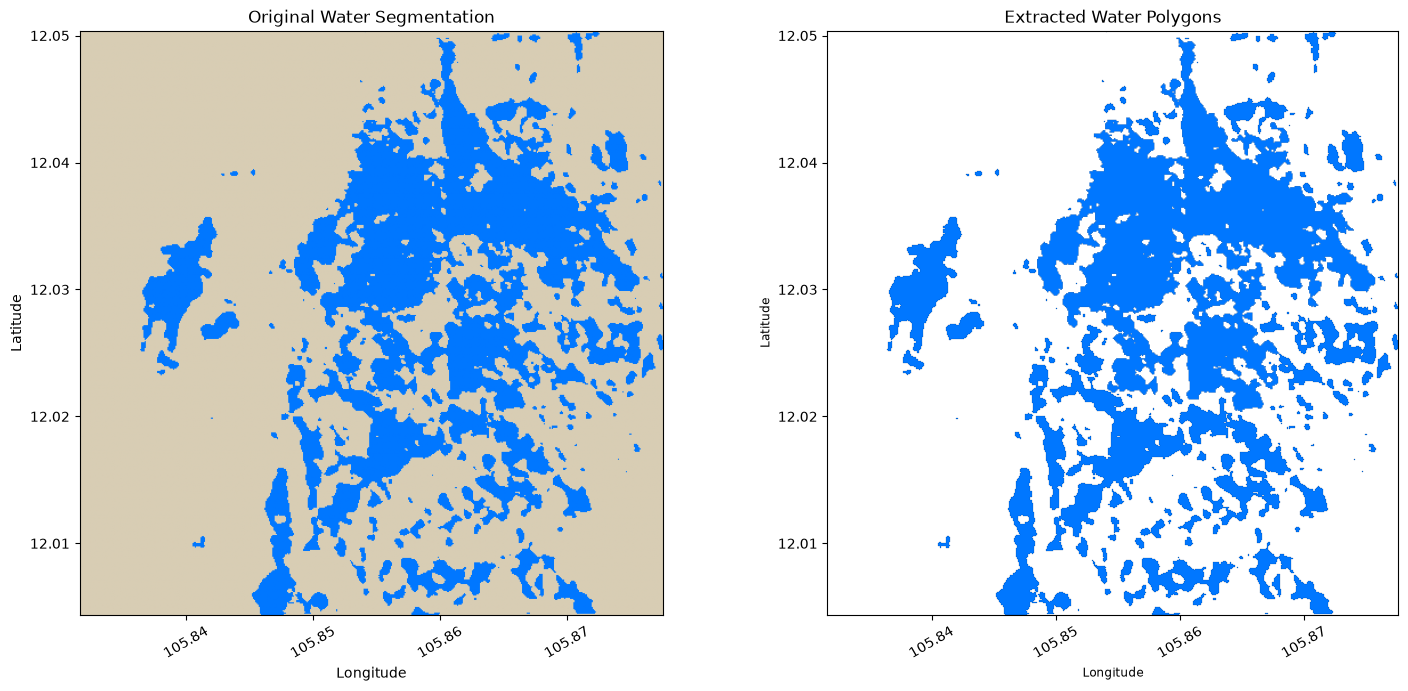

In [31]:
import geopandas as gpd

water_gdf = gpd.GeoDataFrame(
    [
        {
            **region.to_dict(),
            "geometry": region.geometry
        }
        for region in vector_result.regions
    ],
    geometry="geometry",
    crs=vector_result.crs
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7)
)

axes[0].imshow(
    exported_mask,
    cmap=mask_cmap,
    vmin=-1,
    vmax=1,
    extent=extent
)

axes[0].set_title(
    "Original Water Segmentation"
)

water_gdf.plot(
    ax=axes[1],
    color="#0077ff",
    edgecolor="#003c80",
    linewidth=0.15
)

axes[1].set_title(
    "Extracted Water Polygons"
)

for ax in axes:

    ax.set_xlim(
        geo_info.bounds[0],
        geo_info.bounds[2]
    )

    ax.set_ylim(
        geo_info.bounds[1],
        geo_info.bounds[3]
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.ticklabel_format(
        style="plain",
        useOffset=False
    )

    ax.tick_params(
        axis="x",
        labelrotation=30
    )

plt.tight_layout()
plt.show()

In [32]:
from dataclasses import replace

small_metadata = replace(
    metadata,
    width=5,
    height=5
)

test_mask = np.zeros(
    (5, 5),
    dtype=np.int8
)

test_mask[0, 0] = 1
test_mask[0, 1] = 1

test_mask[3, 3] = 1
test_mask[4, 4] = 1

test_mask[2, 2] = -1

synthetic_result = vectorizer.vectorize(
    test_mask,
    small_metadata
)

assert synthetic_result.region_count == 3

print("[PASS] Horizontal connectivity")
print("[PASS] Diagonal region separation")
print("[PASS] Invalid pixel exclusion")

for label in [0, -1]:

    empty_result = vectorizer.vectorize(
        np.full(
            (5, 5),
            label,
            dtype=np.int8
        ),
        small_metadata
    )

    assert empty_result.region_count == 0
    assert empty_result.total_area_m2 == 0
    assert empty_result.largest_region is None

    print(f"[PASS] Empty water result: {label}")

print("\nSynthetic vectorization PASSED!")

[PASS] Horizontal connectivity
[PASS] Diagonal region separation
[PASS] Invalid pixel exclusion
[PASS] Empty water result: 0
[PASS] Empty water result: -1

Synthetic vectorization PASSED!


In [33]:
expect_rejection(
    "Incorrect mask dimensions",
    lambda: vectorizer.vectorize(
        np.zeros((10, 10), dtype=np.int8),
        metadata
    )
)

expect_rejection(
    "Incorrect mask dtype",
    lambda: vectorizer.vectorize(
        exported_mask.astype(np.float32),
        metadata
    )
)

expect_rejection(
    "Invalid segmentation labels",
    lambda: vectorizer.vectorize(
        np.full(
            exported_mask.shape,
            5,
            dtype=np.int8
        ),
        metadata
    )
)

expect_rejection(
    "Maximum pixel limit",
    lambda: WaterVectorizer(
        max_pixels=100
    ).vectorize(
        exported_mask,
        metadata
    )
)

expect_rejection(
    "Maximum region limit",
    lambda: WaterVectorizer(
        max_regions=1
    ).vectorize(
        test_mask,
        small_metadata
    )
)

print("\nAll vectorization rejection tests PASSED!")

[PASS] Incorrect mask dimensions
Reason: Mask dimensions do not match raster.

[PASS] Incorrect mask dtype
Reason: Mask must have int8 dtype.

[PASS] Invalid segmentation labels
Reason: Invalid segmentation labels.

[PASS] Maximum pixel limit
Reason: Raster exceeds vectorization pixel limit.

[PASS] Maximum region limit
Reason: Maximum water region limit exceeded.


All vectorization rejection tests PASSED!


In [34]:
from floodvision.inference.geometry_processor import (
    GeometryProcessor
)

geometry_processor = GeometryProcessor(
    tolerance_m=5.0,
    max_area_change_percentage=1.0
)

print("Geometry processor initialized!")

print(
    "Tolerance:",
    geometry_processor.tolerance_m,
    "meters"
)

print(
    "Maximum area change:",
    geometry_processor.max_area_change_percentage,
    "%"
)

Geometry processor initialized!
Tolerance: 5.0 meters
Maximum area change: 1.0 %


In [35]:
start = time.perf_counter()

processed_vectors = geometry_processor.process(
    vector_result
)

geometry_processing_ms = (
    time.perf_counter() - start
) * 1000

print("=" * 55)
print("GEOMETRY PROCESSING RESULTS")
print("=" * 55)

print(
    json.dumps(
        processed_vectors.to_summary(),
        indent=4,
        allow_nan=False
    )
)

print(
    "\nProcessing time:",
    round(geometry_processing_ms, 4),
    "ms"
)

print("\nGeometry processing PASSED!")

GEOMETRY PROCESSING RESULTS
{
    "crs": "EPSG:4326",
    "tolerance_m": 5.0,
    "max_area_change_percentage": 1.0,
    "region_count": 182,
    "repaired_regions": 0,
    "simplified_regions": 124,
    "original_vertices": 10239,
    "processed_vertices": 8087,
    "vertex_reduction_percentage": 21.0176775075691,
    "original_area_m2": 6425933.066247962,
    "processed_area_m2": 6425933.0780409
}

Processing time: 157.7574 ms

Geometry processing PASSED!


In [36]:
assert (
    processed_vectors.region_count
    == vector_result.region_count
)

for region in processed_vectors.regions:

    assert region.geometry.is_valid

    assert not region.geometry.is_empty

    assert region.area_m2 > 0

    assert region.geometry.geom_type in (
        "Polygon",
        "MultiPolygon"
    )

    assert (
        region.area_change_percentage
        <= 1.0 + 1e-8
    )

    assert (
        region.processed_vertices
        <= region.original_vertices
    )

print("[PASS] Region count preservation")
print("[PASS] Geometry validity")
print("[PASS] Positive geographical areas")
print("[PASS] Area change constraints")
print("[PASS] Vertex count constraints")

print("\nGeometry integrity PASSED!")

[PASS] Region count preservation
[PASS] Geometry validity
[PASS] Positive geographical areas
[PASS] Area change constraints
[PASS] Vertex count constraints

Geometry integrity PASSED!


In [37]:
geometry_df = pd.DataFrame([
    region.to_dict()
    for region in processed_vectors.regions
])

print("=" * 55)
print("GEOMETRY OPTIMIZATION ANALYTICS")
print("=" * 55)

print(
    "Original vertices:",
    processed_vectors.original_vertices
)

print(
    "Processed vertices:",
    processed_vectors.processed_vertices
)

print(
    "Vertex reduction:",
    round(
        processed_vectors.vertex_reduction_percentage,
        4
    ),
    "%"
)

print(
    "Maximum region area change:",
    geometry_df["area_change_percentage"].max(),
    "%"
)

print(
    "Mean region area change:",
    geometry_df["area_change_percentage"].mean(),
    "%"
)

display(
    geometry_df.sort_values(
        "original_vertices",
        ascending=False
    ).head(10)
)

GEOMETRY OPTIMIZATION ANALYTICS
Original vertices: 10239
Processed vertices: 8087
Vertex reduction: 21.0177 %
Maximum region area change: 2.7372176755403826e-05 %
Mean region area change: 2.1279356693158833e-06 %


,region_id,original_area_m2,area_m2,area_km2,area_hectares,original_vertices,processed_vertices,area_change_percentage,vertex_reduction_percentage,repaired,simplified
102,103,3.526188e+06,3.526188e+06,3.526188,352.618758,3642,2868,8.208118e-08,21.252059,False,True
148,149,3.506377e+05,3.506377e+05,0.350638,35.063775,687,543,2.727716e-07,20.960699,False,True
159,160,5.258100e+05,5.258100e+05,0.525810,52.580999,656,546,1.794347e-07,16.768293,False,True
79,80,1.731258e+05,1.731258e+05,0.173126,17.312581,366,284,1.259976e-08,22.404372,False,True
74,75,3.209725e+05,3.209725e+05,0.320972,32.097249,312,252,1.946416e-07,19.230769,False,True
180,181,2.274783e+05,2.274783e+05,0.227478,22.747827,275,221,1.380291e-07,19.636364,False,True
171,172,1.373628e+05,1.373628e+05,0.137363,13.736283,260,202,1.397999e-07,22.307692,False,True
21,22,7.766339e+04,7.766339e+04,0.077663,7.766339,167,127,1.013618e-07,23.952096,False,True
172,173,6.046672e+04,6.046672e+04,0.060467,6.046672,155,117,2.164938e-07,24.516129,False,True
142,143,9.584938e+04,9.584938e+04,0.095849,9.584938,145,113,4.593971e-08,22.068966,False,True


In [38]:
from shapely.geometry import Polygon

invalid_polygon = Polygon([
    (105.84, 12.01),
    (105.85, 12.02),
    (105.84, 12.02),
    (105.85, 12.01),
    (105.84, 12.01)
])

assert not invalid_polygon.is_valid

repaired_polygon = (
    geometry_processor.repair_geometry(
        invalid_polygon
    )
)

print(
    "Original validity:",
    invalid_polygon.is_valid
)

print(
    "Repaired validity:",
    repaired_polygon.is_valid
)

print(
    "Repaired geometry type:",
    repaired_polygon.geom_type
)

assert repaired_polygon.is_valid
assert not repaired_polygon.is_empty

assert repaired_polygon.geom_type in (
    "Polygon",
    "MultiPolygon"
)

print("\nGeometry repair PASSED!")

Original validity: False
Repaired validity: True
Repaired geometry type: MultiPolygon

Geometry repair PASSED!


In [39]:
benchmark_records = []

for tolerance in [0, 2.5, 5, 10, 20]:

    processor = GeometryProcessor(
        tolerance_m=tolerance,
        max_area_change_percentage=1.0
    )

    start = time.perf_counter()

    output = processor.process(
        vector_result
    )

    elapsed_ms = (
        time.perf_counter() - start
    ) * 1000

    area_change = (
        abs(
            output.processed_area_m2
            - output.original_area_m2
        )
        / output.original_area_m2
        * 100
    )

    benchmark_records.append({
        "tolerance_m": tolerance,

        "regions": output.region_count,

        "vertices": output.processed_vertices,

        "vertex_reduction_percentage":
            output.vertex_reduction_percentage,

        "total_area_change_percentage":
            area_change,

        "simplified_regions": sum(
            r.simplified
            for r in output.regions
        ),

        "processing_ms": elapsed_ms
    })

geometry_benchmark_df = pd.DataFrame(
    benchmark_records
)

display(
    geometry_benchmark_df.round(6)
)

,tolerance_m,regions,vertices,vertex_reduction_percentage,total_area_change_percentage,simplified_regions,processing_ms
0,0.0,182,10239,0.000000,0.000000,0,74.8243
1,2.5,182,10239,0.000000,0.000000,0,129.6791
2,5.0,182,8087,21.017678,0.000000,124,115.5549
3,10.0,182,4964,51.518703,0.108915,40,82.8596
4,20.0,182,6684,34.720188,0.167910,10,66.2253


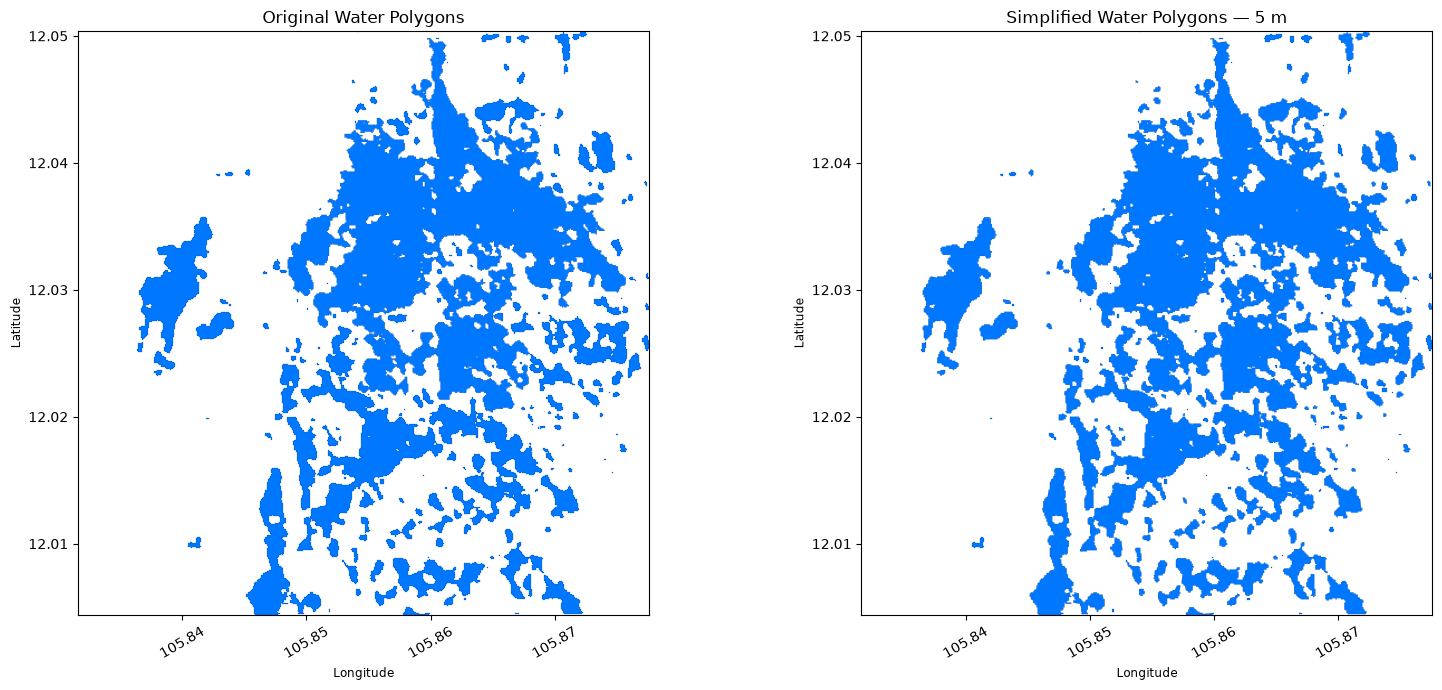

In [40]:
processed_gdf = gpd.GeoDataFrame(
    [
        {
            **region.to_dict(),
            "geometry": region.geometry
        }
        for region in processed_vectors.regions
    ],
    geometry="geometry",
    crs="EPSG:4326"
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

water_gdf.plot(
    ax=axes[0],
    color="#0077ff",
    edgecolor="#003c80",
    linewidth=0.15
)

processed_gdf.plot(
    ax=axes[1],
    color="#0077ff",
    edgecolor="#003c80",
    linewidth=0.15
)

axes[0].set_title(
    "Original Water Polygons"
)

axes[1].set_title(
    "Simplified Water Polygons — 5 m"
)

for ax in axes:

    ax.set_xlim(
        geo_info.bounds[0],
        geo_info.bounds[2]
    )

    ax.set_ylim(
        geo_info.bounds[1],
        geo_info.bounds[3]
    )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    ax.ticklabel_format(
        style="plain",
        useOffset=False
    )

    ax.tick_params(
        axis="x",
        labelrotation=30
    )

plt.tight_layout()
plt.show()

In [41]:
simplified_raster = rasterize(
    [
        (region.geometry, 1)
        for region in processed_vectors.regions
    ],
    out_shape=exported_mask.shape,
    transform=metadata.transform,
    fill=0,
    all_touched=False,
    dtype="uint8"
)

original_binary = (
    exported_mask == 1
)

simplified_binary = (
    simplified_raster == 1
)

intersection = np.count_nonzero(
    original_binary & simplified_binary
)

union = np.count_nonzero(
    original_binary | simplified_binary
)

geometry_iou = (
    intersection / union
    if union > 0
    else 1.0
)

changed_pixels = np.count_nonzero(
    original_binary != simplified_binary
)

invalid_encroachment = np.count_nonzero(
    simplified_binary
    & (exported_mask == -1)
)

print("=" * 55)
print("SIMPLIFIED GEOMETRY FIDELITY")
print("=" * 55)

print(
    "Original water pixels:",
    original_binary.sum()
)

print(
    "Simplified water pixels:",
    simplified_binary.sum()
)

print("Changed pixels:", changed_pixels)

print(
    "Geometry IoU:",
    round(geometry_iou, 6)
)

print(
    "Invalid pixel encroachment:",
    invalid_encroachment
)

print(
    "Geometry agreement:",
    round(geometry_iou * 100, 4),
    "%"
)

SIMPLIFIED GEOMETRY FIDELITY
Original water pixels: 66106
Simplified water pixels: 66106
Changed pixels: 0
Geometry IoU: 1.0
Invalid pixel encroachment: 0
Geometry agreement: 100.0 %


In [42]:
empty_vectors = vectorizer.vectorize(
    np.zeros(
        exported_mask.shape,
        dtype=np.int8
    ),
    metadata
)

empty_processed = geometry_processor.process(
    empty_vectors
)

assert empty_processed.region_count == 0
assert empty_processed.original_vertices == 0
assert empty_processed.processed_vertices == 0

print("[PASS] Empty vector result")

expect_rejection(
    "Negative tolerance",
    lambda: GeometryProcessor(
        tolerance_m=-5
    )
)

expect_rejection(
    "NaN tolerance",
    lambda: GeometryProcessor(
        tolerance_m=float("nan")
    )
)

expect_rejection(
    "Invalid area change",
    lambda: GeometryProcessor(
        max_area_change_percentage=150
    )
)

expect_rejection(
    "Invalid vectorization input",
    lambda: geometry_processor.process(None)
)

print("\nAll geometry rejection tests PASSED!")

[PASS] Empty vector result
[PASS] Negative tolerance
Reason: Invalid simplification tolerance.

[PASS] NaN tolerance
Reason: Invalid simplification tolerance.

[PASS] Invalid area change
Reason: Invalid maximum area change.

[PASS] Invalid vectorization input
Reason: Expected VectorizationResult.


All geometry rejection tests PASSED!


In [43]:
geometry_df.to_csv(
    EXPORT_DIR / "geometry_processing_results.csv",
    index=False
)

geometry_benchmark_df.to_csv(
    EXPORT_DIR / "geometry_simplification_benchmark.csv",
    index=False
)

geometry_summary = {
    **processed_vectors.to_summary(),

    "processing_ms": geometry_processing_ms,

    "reconstruction_iou": geometry_iou,

    "changed_pixels": int(changed_pixels),

    "invalid_pixel_encroachment":
        int(invalid_encroachment)
}

with open(
    EXPORT_DIR / "geometry_processing_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        geometry_summary,
        file,
        indent=4,
        allow_nan=False
    )

print("Geometry processing artifacts saved!")

Geometry processing artifacts saved!


In [44]:
from floodvision.inference.vector_exporter import (
    VectorExporter
)

vector_exporter = VectorExporter(
    model_version="1.0.0",
    threshold=0.5
)

print("Vector exporter initialized!")

Vector exporter initialized!


In [45]:
original_geojson_path = vector_exporter.export(
    result=vector_result,
    output_path=(
        EXPORT_DIR /
        f"{sample_id}_water_regions_original.geojson"
    ),
    source_file=sample_path.name,
    overwrite=True
)

simplified_geojson_path = vector_exporter.export(
    result=processed_vectors,
    output_path=(
        EXPORT_DIR /
        f"{sample_id}_water_regions_simplified.geojson"
    ),
    source_file=sample_path.name,
    overwrite=True
)

print("=" * 55)
print("GEOJSON EXPORT RESULTS")
print("=" * 55)

for path in [
    original_geojson_path,
    simplified_geojson_path
]:

    print("\nFile:", path.name)

    print(
        "Size:",
        round(path.stat().st_size / 1024, 4),
        "KiB"
    )

print("\nGeoJSON export PASSED!")

GEOJSON EXPORT RESULTS

File: Mekong_1111068_water_regions_original.geojson
Size: 456.1025 KiB

File: Mekong_1111068_water_regions_simplified.geojson
Size: 411.3574 KiB

GeoJSON export PASSED!


In [46]:
original_bytes = (
    original_geojson_path.stat().st_size
)

simplified_bytes = (
    simplified_geojson_path.stat().st_size
)

size_reduction = (
    1 - simplified_bytes / original_bytes
) * 100

print("=" * 55)
print("GEOJSON STORAGE OPTIMIZATION")
print("=" * 55)

print("Original bytes:", original_bytes)

print("Simplified bytes:", simplified_bytes)

print(
    "File size reduction:",
    round(size_reduction, 4),
    "%"
)

print(
    "Vertex reduction:",
    round(
        processed_vectors.vertex_reduction_percentage,
        4
    ),
    "%"
)

GEOJSON STORAGE OPTIMIZATION
Original bytes: 467049
Simplified bytes: 421230
File size reduction: 9.8103 %
Vertex reduction: 21.0177 %


In [47]:
from shapely.geometry import shape

with open(
    original_geojson_path,
    encoding="utf-8"
) as file:

    original_geojson = json.load(file)

with open(
    simplified_geojson_path,
    encoding="utf-8"
) as file:

    simplified_geojson = json.load(file)

for collection in [
    original_geojson,
    simplified_geojson
]:

    assert collection["type"] == "FeatureCollection"

    assert len(collection["features"]) == 182

    assert "crs" not in collection

    assert len(collection["bbox"]) == 4

    region_ids = set()

    for feature in collection["features"]:

        assert feature["type"] == "Feature"

        geometry = shape(
            feature["geometry"]
        )

        assert geometry.is_valid
        assert not geometry.is_empty

        properties = feature["properties"]

        assert properties["area_m2"] > 0

        assert properties["classification"] == (
            "predicted_water"
        )

        assert feature["id"] == properties["region_id"]

        assert feature["id"] not in region_ids

        region_ids.add(feature["id"])

    print(
        "[PASS]",
        collection["metadata"]["geometry_variant"]
    )

print("\nGeoJSON structure validation PASSED!")

[PASS] original
[PASS] processed

GeoJSON structure validation PASSED!


In [48]:
import math

original_areas = {
    feature["id"]: feature["properties"]["area_m2"]

    for feature in original_geojson["features"]
}

simplified_areas = {
    feature["id"]: feature["properties"]["area_m2"]

    for feature in simplified_geojson["features"]
}

assert original_areas == simplified_areas

original_total = math.fsum(
    original_areas.values()
)

simplified_total = math.fsum(
    simplified_areas.values()
)

print("Original area:", original_total)

print("Simplified reported area:", simplified_total)

print(
    "Difference:",
    abs(original_total - simplified_total)
)

print("\nCanonical area preservation PASSED!")

Original area: 6425933.066247962
Simplified reported area: 6425933.066247962
Difference: 0.0

Canonical area preservation PASSED!


In [49]:
for collection in [
    original_geojson,
    simplified_geojson
]:

    restored_mask = rasterize(
        [
            (
                shape(feature["geometry"]),
                1
            )

            for feature in collection["features"]
        ],
        out_shape=exported_mask.shape,
        transform=metadata.transform,
        fill=0,
        all_touched=False,
        dtype="uint8"
    )

    differences = np.count_nonzero(
        restored_mask != (exported_mask == 1)
    )

    print(
        collection["metadata"]["geometry_variant"],
        "| Different pixels:",
        differences
    )

    assert differences == 0

print("\nGeoJSON round-trip reconstruction PASSED!")

original | Different pixels: 0
processed | Different pixels: 0

GeoJSON round-trip reconstruction PASSED!


In [50]:
from shapely.ops import unary_union

from pyproj import Transformer

from shapely.ops import transform

metric_transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32648",
    always_xy=True
)

for collection in [
    original_geojson,
    simplified_geojson
]:

    geometries = [
        transform(
            metric_transformer.transform,
            shape(feature["geometry"])
        )

        for feature in collection["features"]
    ]

    summed_area = math.fsum(
        geometry.area
        for geometry in geometries
    )

    union_area = unary_union(
        geometries
    ).area

    overlap_area = max(
        0.0,
        summed_area - union_area
    )

    print(
        collection["metadata"]["geometry_variant"],
        "| Overlap area:",
        overlap_area,
        "m²"
    )

    assert overlap_area <= 0.01

print("\nInter-region overlap validation PASSED!")

C:\Users\User\AppData\Local\Temp\ipykernel_524020\1307525678.py:19: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  transform(


original | Overlap area: 0.0 m²
processed | Overlap area: 5.587935447692871e-09 m²

Inter-region overlap validation PASSED!


In [51]:
original_loaded_gdf = gpd.read_file(
    original_geojson_path
)

simplified_loaded_gdf = gpd.read_file(
    simplified_geojson_path
)

assert len(original_loaded_gdf) == 182

assert len(simplified_loaded_gdf) == 182

assert original_loaded_gdf.crs.to_epsg() == 4326

assert simplified_loaded_gdf.crs.to_epsg() == 4326

assert original_loaded_gdf.geometry.is_valid.all()

assert simplified_loaded_gdf.geometry.is_valid.all()

print("[PASS] GeoPandas loading")
print("[PASS] CRS interoperability")
print("[PASS] Feature count")
print("[PASS] Geometry integrity")

display(
    simplified_loaded_gdf[
        [
            "region_id",
            "area_km2",
            "classification",
            "geometry"
        ]
    ].head()
)

print("\nGIS interoperability PASSED!")

[PASS] GeoPandas loading
[PASS] CRS interoperability
[PASS] Feature count
[PASS] Geometry integrity


,region_id,area_km2,classification,geometry
0,1,0.000097,predicted_water,"POLYGON ((105.85406 12.05036, 105.85406 12.050..."
1,2,0.000292,predicted_water,"POLYGON ((105.86044 12.04982, 105.86044 12.049..."
2,3,0.005054,predicted_water,"POLYGON ((105.87203 12.05036, 105.87203 12.050..."
3,4,0.007387,predicted_water,"POLYGON ((105.86448 12.05018, 105.86448 12.050..."
4,5,0.002138,predicted_water,"POLYGON ((105.8661 12.05, 105.8661 12.04955, 1..."



GIS interoperability PASSED!


In [52]:
empty_geojson_path = vector_exporter.export(
    result=empty_processed,
    output_path=(
        EXPORT_DIR / "empty_water_regions.geojson"
    ),
    source_file="synthetic_empty.tif",
    overwrite=True
)

with open(
    empty_geojson_path,
    encoding="utf-8"
) as file:

    empty_geojson = json.load(file)

assert empty_geojson["type"] == "FeatureCollection"

assert empty_geojson["features"] == []

assert empty_geojson["metadata"]["region_count"] == 0

assert "bbox" not in empty_geojson

print(
    json.dumps(
        empty_geojson,
        indent=4
    )
)

print("\nEmpty GeoJSON export PASSED!")

{
    "type": "FeatureCollection",
    "metadata": {
        "project": "FloodVision AI",
        "task": "binary_water_segmentation",
        "source_file": "synthetic_empty.tif",
        "model_version": "1.0.0",
        "threshold": 0.5,
        "region_count": 0,
        "geometry_variant": "processed",
        "total_water_area_m2": 0.0,
        "simplification_tolerance_m": 5.0,
        "vertex_reduction_percentage": 0.0
    },
    "features": []
}

Empty GeoJSON export PASSED!


In [53]:
expect_rejection(
    "Unsupported vector result",
    lambda: vector_exporter.build_feature_collection(
        None,
        "sample.tif"
    )
)

expect_rejection(
    "Invalid output extension",
    lambda: vector_exporter.export(
        vector_result,
        EXPORT_DIR / "invalid.txt",
        sample_path.name
    )
)

expect_rejection(
    "Existing output protection",
    lambda: vector_exporter.export(
        vector_result,
        original_geojson_path,
        sample_path.name,
        overwrite=False
    )
)

expect_rejection(
    "Invalid threshold",
    lambda: VectorExporter(
        threshold=1.5
    )
)

print("\nAll GeoJSON rejection tests PASSED!")

[PASS] Unsupported vector result
Reason: Unsupported vector result.

[PASS] Invalid output extension
Reason: Output must use .geojson extension.

[PASS] Existing output protection
Reason: Output already exists: D:\FloodVision-AI\ml\artifacts\geospatial_validation\Mekong_1111068_water_regions_original.geojson

[PASS] Invalid threshold
Reason: Invalid prediction threshold.


All GeoJSON rejection tests PASSED!


In [54]:
geojson_export_df = pd.DataFrame([
    {
        "geometry_variant": "original",
        "regions": vector_result.region_count,
        "vertices": processed_vectors.original_vertices,
        "file_size_bytes": original_bytes,
        "file_size_kib": original_bytes / 1024,
        "water_area_m2": original_total
    },
    {
        "geometry_variant": "simplified",
        "regions": processed_vectors.region_count,
        "vertices": processed_vectors.processed_vertices,
        "file_size_bytes": simplified_bytes,
        "file_size_kib": simplified_bytes / 1024,
        "water_area_m2": simplified_total
    }
])

geojson_export_df.to_csv(
    EXPORT_DIR / "geojson_export_benchmark.csv",
    index=False
)

display(geojson_export_df)

print("\nGeoJSON benchmark saved!")

,geometry_variant,regions,vertices,file_size_bytes,file_size_kib,water_area_m2
0,original,182,10239,467049,456.102539,6.425933e+06
1,simplified,182,8087,421230,411.357422,6.425933e+06



GeoJSON benchmark saved!


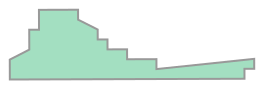

In [56]:
from shapely import transform
transform(
    shape(feature["geometry"]),
    metric_transformer.transform,
    interleaved=False
)

In [57]:
from floodvision.inference.geometry_utils import (
    repair_polygonal_geometry
)

from rasterio.features import rasterize
from dataclasses import replace

# Diagonally connected pixels can produce
# self-touching polygon boundaries.

repair_test_mask = np.zeros(
    (5, 5),
    dtype=np.int8
)

repair_test_mask[1, 1] = 1
repair_test_mask[2, 2] = 1
repair_test_mask[3, 3] = 1

repair_metadata = replace(
    metadata,
    width=5,
    height=5
)

repair_vectorizer = WaterVectorizer(
    connectivity=8
)

repair_result = repair_vectorizer.vectorize(
    repair_test_mask,
    repair_metadata
)

assert repair_result.region_count == 1

for region in repair_result.regions:

    assert region.geometry.is_valid
    assert not region.geometry.is_empty

repair_reconstructed = rasterize(
    [
        (region.geometry, 1)
        for region in repair_result.regions
    ],
    out_shape=repair_test_mask.shape,
    transform=repair_metadata.transform,
    fill=0,
    dtype="uint8"
)

assert np.array_equal(
    repair_reconstructed,
    repair_test_mask == 1
)

print("[PASS] Eight-connectivity extraction")
print("[PASS] Valid polygonal geometries")
print("[PASS] Exact raster reconstruction")

print("\nGeometry repair integration PASSED!")

[PASS] Eight-connectivity extraction
[PASS] Valid polygonal geometries
[PASS] Exact raster reconstruction

Geometry repair integration PASSED!


In [58]:
hole_mask = np.zeros(
    (7, 7),
    dtype=np.int8
)

hole_mask[1:6, 1:6] = 1
hole_mask[2:5, 2:5] = 0
hole_mask[3, 3] = -1

hole_metadata = replace(
    metadata,
    width=7,
    height=7
)

hole_result = vectorizer.vectorize(
    hole_mask,
    hole_metadata
)

assert hole_result.region_count == 1

hole_geometry = (
    hole_result.regions[0].geometry
)

assert hole_geometry.geom_type == "Polygon"
assert len(hole_geometry.interiors) == 1

hole_reconstructed = rasterize(
    [(hole_geometry, 1)],
    out_shape=hole_mask.shape,
    transform=hole_metadata.transform,
    fill=0,
    dtype="uint8"
)

assert np.array_equal(
    hole_reconstructed,
    hole_mask == 1
)

assert hole_reconstructed[3, 3] == 0

print("[PASS] Interior polygon preservation")
print("[PASS] Non-water island preservation")
print("[PASS] Invalid pixel exclusion")
print("[PASS] Exact reconstruction")

print("\nPolygon hole validation PASSED!")

[PASS] Interior polygon preservation
[PASS] Non-water island preservation
[PASS] Invalid pixel exclusion
[PASS] Exact reconstruction

Polygon hole validation PASSED!


In [59]:
from pathlib import Path

required_artifacts = [
    f"{sample_id}_water_mask.tif",
    f"{sample_id}_water_probability.tif",
    f"{sample_id}_water_regions_original.geojson",
    f"{sample_id}_water_regions_simplified.geojson",
    "geometry_processing_results.csv",
    "geometry_simplification_benchmark.csv",
    "geometry_processing_summary.json",
    "geojson_export_benchmark.csv"
]

print("=" * 60)
print("GEOSPATIAL ARTIFACT AUDIT")
print("=" * 60)

artifact_records = []

for filename in required_artifacts:

    path = EXPORT_DIR / filename

    assert path.is_file(), (
        f"Missing artifact: {filename}"
    )

    assert path.stat().st_size > 0

    artifact_records.append({
        "filename": filename,
        "size_bytes": path.stat().st_size
    })

    print(
        f"[PASS] {filename} | "
        f"{path.stat().st_size / 1024:.2f} KiB"
    )

print(
    "\nVerified artifacts:",
    len(artifact_records)
)

print("\nArtifact audit PASSED!")

GEOSPATIAL ARTIFACT AUDIT
[PASS] Mekong_1111068_water_mask.tif | 10.89 KiB
[PASS] Mekong_1111068_water_probability.tif | 933.86 KiB
[PASS] Mekong_1111068_water_regions_original.geojson | 456.10 KiB
[PASS] Mekong_1111068_water_regions_simplified.geojson | 411.36 KiB
[PASS] geometry_processing_results.csv | 23.10 KiB
[PASS] geometry_simplification_benchmark.csv | 0.42 KiB
[PASS] geometry_processing_summary.json | 0.51 KiB
[PASS] geojson_export_benchmark.csv | 0.19 KiB

Verified artifacts: 8

Artifact audit PASSED!


In [60]:
geospatial_report = {

    "project": "FloodVision AI",

    "phase": "41",

    "model_version": "1.0.0",

    "sample_id": sample_id,

    "task": "binary_water_segmentation",

    "geospatial_metadata": geo_info.to_dict(),

    "area_analytics": area_stats.to_dict(),

    "vectorization": {
        **vector_result.to_summary(),
        "processing_ms": vectorization_ms
    },

    "geometry_processing": {
        **processed_vectors.to_summary(),
        "reconstruction_iou": float(geometry_iou),
        "changed_pixels": int(changed_pixels),
        "invalid_pixel_encroachment": int(
            invalid_encroachment
        )
    },

    "geojson_export": {
        "original_bytes": original_bytes,
        "simplified_bytes": simplified_bytes,
        "size_reduction_percentage": size_reduction
    },

    "artifacts": artifact_records,

    "deployment_status": "research_prototype",

    "limitations": [
        "Predicted water is not confirmed flood extent.",
        "Area analytics currently supports north-up WGS84 rasters.",
        "Vectorization has configured resource limits.",
        "Simplification fidelity requires per-raster validation.",
        "Antimeridian-crossing geometries are outside supported scope."
    ]
}

report_path = (
    EXPORT_DIR / "geospatial_validation_report.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        geospatial_report,
        file,
        indent=4,
        allow_nan=False
    )

print("Geospatial report saved!")
print("Path:", report_path)

Geospatial report saved!
Path: D:\FloodVision-AI\ml\artifacts\geospatial_validation\geospatial_validation_report.json


In [61]:
print("=" * 60)
print("FLOODVISION AI - PHASE 41 FINAL AUDIT")
print("=" * 60)

checks = {

    "Model version": (
        vector_exporter.model_version == "1.0.0"
    ),

    "Region preservation": (
        vector_result.region_count
        == processed_vectors.region_count
    ),

    "Raster-vector area consistency": np.isclose(
        area_stats.water_area_m2,
        vector_result.total_area_m2,
        rtol=1e-4,
        atol=1.0
    ),

    "Geometry validity": all(
        region.geometry.is_valid
        for region in processed_vectors.regions
    ),

    "Geometry reconstruction": (
        geometry_iou == 1.0
    ),

    "Invalid pixel protection": (
        invalid_encroachment == 0
    ),

    "Canonical area preservation": (
        original_areas == simplified_areas
    ),

    "GeoJSON feature preservation": (
        len(original_geojson["features"])
        == len(simplified_geojson["features"])
        == vector_result.region_count
    ),

    "GIS interoperability": (
        original_loaded_gdf.crs.to_epsg() == 4326
        and simplified_loaded_gdf.crs.to_epsg() == 4326
        and len(original_loaded_gdf)
        == len(simplified_loaded_gdf)
        == vector_result.region_count
        and original_loaded_gdf.geometry.is_valid.all()
        and simplified_loaded_gdf.geometry.is_valid.all()
    ),

    "Geometry repair integration": np.array_equal(
        repair_reconstructed,
        repair_test_mask == 1
    ),

    "Polygon hole preservation": np.array_equal(
        hole_reconstructed,
        hole_mask == 1
    ),

    "Required artifacts": all(
        (EXPORT_DIR / name).is_file()
        for name in required_artifacts
    ),

    "Final report": report_path.is_file()
}

for name, passed in checks.items():

    print(
        f"[{'PASS' if passed else 'FAIL'}] {name}"
    )

assert all(checks.values())

print("\n" + "=" * 60)
print("PHASE 41 COMPLETED SUCCESSFULLY")
print("=" * 60)

FLOODVISION AI - PHASE 41 FINAL AUDIT
[PASS] Model version
[PASS] Region preservation
[PASS] Raster-vector area consistency
[PASS] Geometry validity
[PASS] Geometry reconstruction
[PASS] Invalid pixel protection
[PASS] Canonical area preservation
[PASS] GeoJSON feature preservation
[PASS] GIS interoperability
[PASS] Geometry repair integration
[PASS] Polygon hole preservation
[PASS] Required artifacts
[PASS] Final report

PHASE 41 COMPLETED SUCCESSFULLY
